In [1]:
from google.colab import files

uploaded = files.upload()

Saving amazon_sales_10k.csv to amazon_sales_10k.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('amazon_sales_10k.csv')

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Dataset shape: (10000, 14)


,order_id,order_date,customer_id,product_id,product_name,category,quantity,price,amount,payment_method,city,state,coupon_used,order_status
0,ORD2023010102327,2023-01-01,23281,1007,Portable SSD 1TB,Electronics,2,659.83,1319.66,UPI,Jaipur,Rajasthan,1,Shipped
1,ORD2023010102604,2023-01-01,52278,1039,Hair Dryer,Beauty,2,689.14,1378.28,UPI,Jaipur,Rajasthan,0,Delivered
2,ORD2023010102714,2023-01-01,75282,1016,Running Shoes,Clothing,2,353.84,707.68,NetBanking,Delhi,Delhi,1,Delivered
3,ORD2023010102902,2023-01-01,99170,1006,Mechanical Keyboard,Electronics,1,24657.88,24657.88,UPI,Noida,Uttar Pradesh,0,Delivered
4,ORD2023010102911,2023-01-01,36234,1048,Tennis Balls (Pack of 3),Sports,2,228.98,457.96,UPI,Surat,Gujarat,0,Delivered


['order_id', 'order_date', 'customer_id', 'product_id', 'product_name', 'category', 'quantity', 'price', 'amount', 'payment_method', 'city', 'state', 'coupon_used', 'order_status']


In [3]:
df.info()
display(df.describe(include="all").T)

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        10000 non-null  object 
 1   order_date      10000 non-null  object 
 2   customer_id     10000 non-null  int64  
 3   product_id      10000 non-null  int64  
 4   product_name    10000 non-null  object 
 5   category        10000 non-null  object 
 6   quantity        10000 non-null  int64  
 7   price           10000 non-null  float64
 8   amount          10000 non-null  float64
 9   payment_method  10000 non-null  object 
 10  city            10000 non-null  object 
 11  state           10000 non-null  object 
 12  coupon_used     10000 non-null  int64  
 13  order_status    10000 non-null  object 
dtypes: float64(2), int64(4), object(8)
memory usage: 1.1+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,10000,10000,ORD2024083009028,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,10000,609,2024-05-04,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,10000.0,NaN,NaN,NaN,54869.3313,26434.111,10005.0,31675.25,54877.5,78010.75,99987.0
product_id,10000.0,NaN,NaN,NaN,1023.8477,14.648132,1001.0,1011.0,1023.0,1036.0,1050.0
product_name,10000,50,Smartwatch Series 5,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,10000,5,Electronics,2458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,10000.0,NaN,NaN,NaN,1.5725,0.729792,1.0,1.0,1.0,2.0,3.0
price,10000.0,NaN,NaN,NaN,3997.834739,5600.862542,85.78,477.195,2097.435,4851.015,30883.99
amount,10000.0,NaN,NaN,NaN,5650.648294,10504.206427,-83139.36,545.8175,2189.35,6680.8525,92651.97
payment_method,10000,5,UPI,4510,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:
order_id          0
order_date        0
customer_id       0
product_id        0
product_name      0
category          0
quantity          0
price             0
amount            0
payment_method    0
city              0
state             0
coupon_used       0
order_status      0
dtype: int64
Duplicate rows: 0


In [4]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

print("Earliest date:", df["order_date"].min())
print("Latest date:", df["order_date"].max())
print("Number of cities:", df["city"].nunique())

Earliest date: 2023-01-01 00:00:00
Latest date: 2024-08-31 00:00:00
Number of cities: 23


In [5]:
df = df.drop_duplicates()

df["city"] = df["city"].astype("string").str.strip().str.title()
df["product_name"] = (
    df["product_name"].astype("string").str.strip()
)
df["category"] = df["category"].astype("string").str.strip()

df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["amount"] = pd.to_numeric(df["amount"], errors="coerce")

df = df.dropna(
    subset=["order_date", "city", "product_name",
            "category", "quantity", "price", "amount"]
)

df = df[
    (df["quantity"] > 0) &
    (df["price"] >= 0) &
    (df["amount"] >= 0)
].copy()

print("Cleaned shape:", df.shape)

Cleaned shape: (9568, 14)


In [6]:
print(df["order_date"].dt.year.value_counts().sort_index())

order_date
2023    5829
2024    3739
Name: count, dtype: int64


In [7]:

print("Dataset size:", df.shape)

print("\nCities:")
print(sorted(df["city"].dropna().unique()))

print("\nNumber of cities:", df["city"].nunique())

print("\nCategories:")
print(df["category"].value_counts())

print("\nOrder statuses:")
print(df["order_status"].value_counts())

print("\nDate range:")
print(df["order_date"].min(), "to", df["order_date"].max())

print("\nInvalid quantities:", (df["quantity"] <= 0).sum())
print("Invalid prices:", (df["price"] < 0).sum())
print("Invalid amounts:", (df["amount"] < 0).sum())


Dataset size: (9568, 14)

Cities:
['Ahmedabad', 'Bengaluru', 'Bhopal', 'Chandigarh', 'Chennai', 'Delhi', 'Dubai', 'Gurugram', 'Hyderabad', 'Indore', 'Jaipur', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Nagpur', 'New York', 'Noida', 'Patna', 'Pune', 'Singapore', 'Surat', 'Thiruvananthapuram']

Number of cities: 23

Categories:
category
Electronics    2346
Clothing       1977
Home           1820
Sports         1738
Beauty         1687
Name: count, dtype: Int64

Order statuses:
order_status
Delivered    8549
Shipped       810
Cancelled     209
Name: count, dtype: int64

Date range:
2023-01-01 00:00:00 to 2024-08-31 00:00:00

Invalid quantities: 0
Invalid prices: 0
Invalid amounts: 0


In [8]:
city_sales = (
    df.groupby("city")
      .agg(
          total_revenue=("amount", "sum"),
          units_sold=("quantity", "sum"),
          transactions=("order_id", "nunique")
      )
      .sort_values("total_revenue", ascending=False)
)

display(city_sales.head(10))

,total_revenue,units_sold,transactions
city,,,
Surat,3138418.82,685,433
Patna,2880708.37,656,406
Thiruvananthapuram,2836469.78,685,433
Pune,2824843.23,590,382
Chennai,2788460.80,681,425
Lucknow,2783870.17,693,438
Kochi,2732517.19,675,423
Ahmedabad,2719084.23,700,444
Chandigarh,2679361.79,667,426


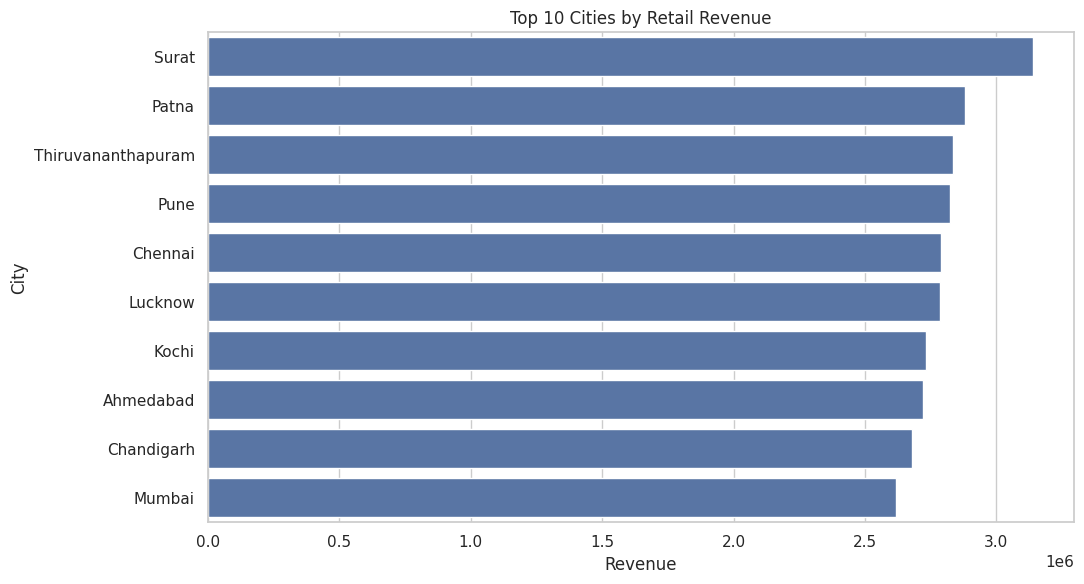

In [9]:
top_cities = city_sales.head(10).reset_index()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_cities,
    x="total_revenue",
    y="city"
)
plt.title("Top 10 Cities by Retail Revenue")
plt.xlabel("Revenue")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [10]:
product_sales = (
    df.groupby("product_name")
      .agg(
          units_sold=("quantity", "sum"),
          revenue=("amount", "sum")
      )
      .sort_values("units_sold", ascending=False)
)

display(product_sales.head(10))

,units_sold,revenue
product_name,,
Bluetooth Headphones,393,896679.85
USB-C Charger,384,422550.00
Smartwatch Series 5,381,1667397.04
Power Bank 10000mAh,379,3023133.71
Laptop Stand,376,6192941.52
Mechanical Keyboard,374,9855191.62
4K Action Camera,374,3554073.35
Wireless Mouse,358,981142.03
Portable SSD 1TB,353,199852.04


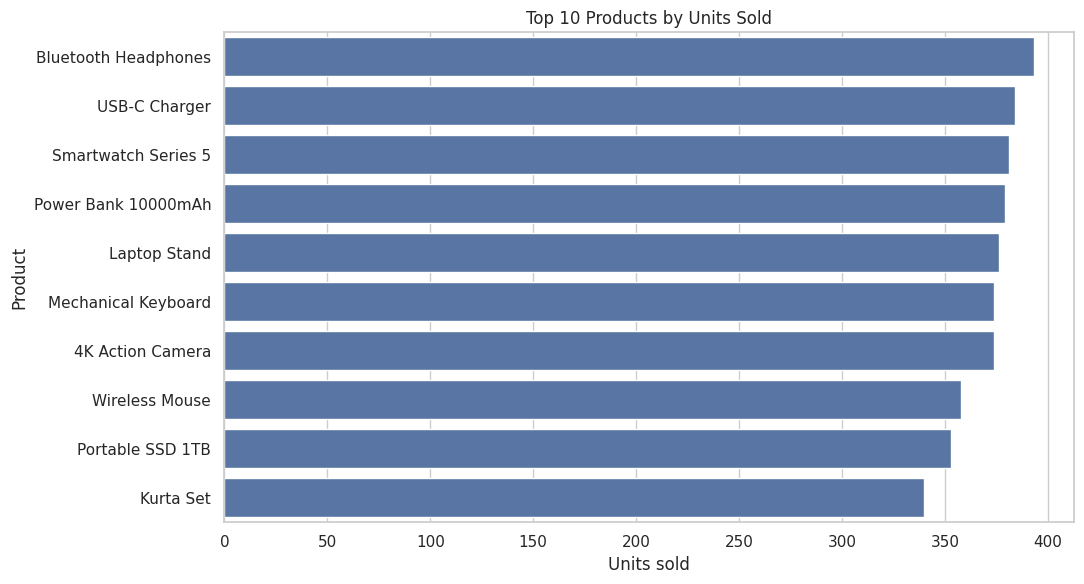

In [11]:
top_products = product_sales.head(10).reset_index()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_products,
    x="units_sold",
    y="product_name"
)
plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [12]:
category_sales = (
    df.groupby("category")
      .agg(
          revenue=("amount", "sum"),
          quantity=("quantity", "sum"),
          average_sale=("amount", "mean")
      )
      .sort_values("revenue", ascending=False)
)

display(category_sales)

,revenue,quantity,average_sale
category,,,
Electronics,32239439.58,3708,13742.301611
Sports,11560132.18,2721,6651.399413
Home,8787114.41,2897,4828.084841
Clothing,3646368.63,3085,1844.394856
Beauty,3015660.67,2642,1787.587830


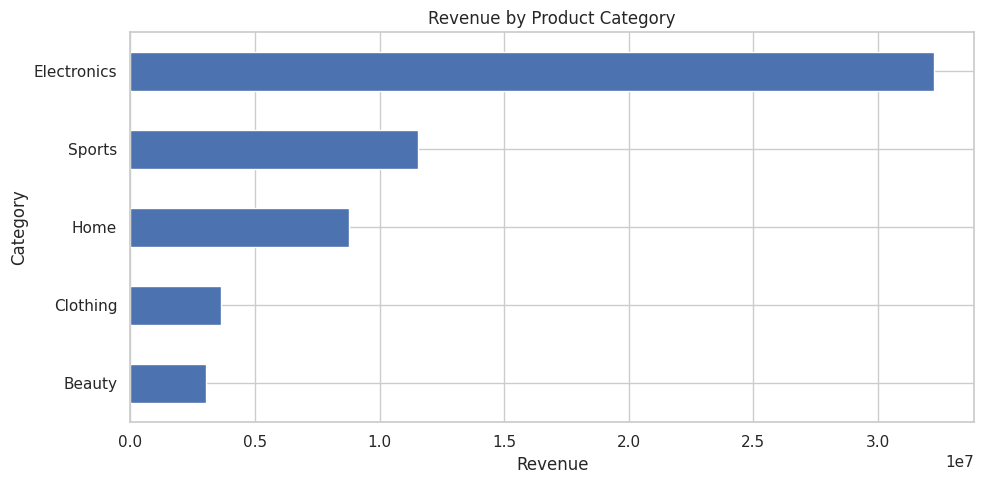

In [13]:
category_sales["revenue"].sort_values().plot(
    kind="barh", figsize=(10, 5)
)

plt.title("Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

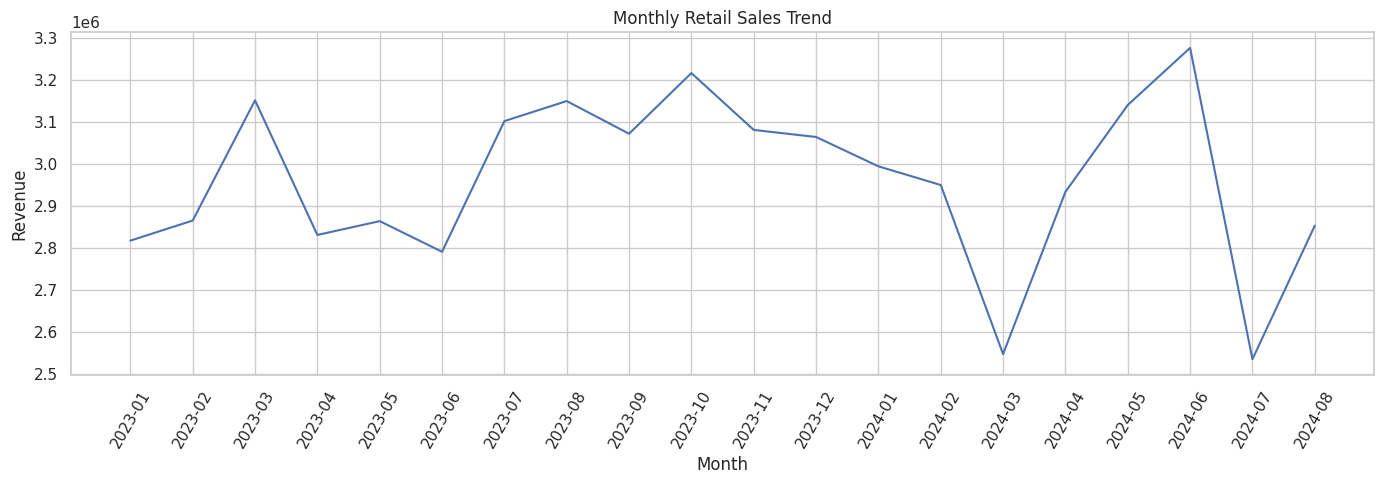

In [14]:
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

monthly_sales = (
    df.groupby("year_month")["amount"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values)
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

             count         mean          sum
coupon_used                                 
0             6800  6130.832581  41689661.55
1             2768  6343.588844  17559053.92


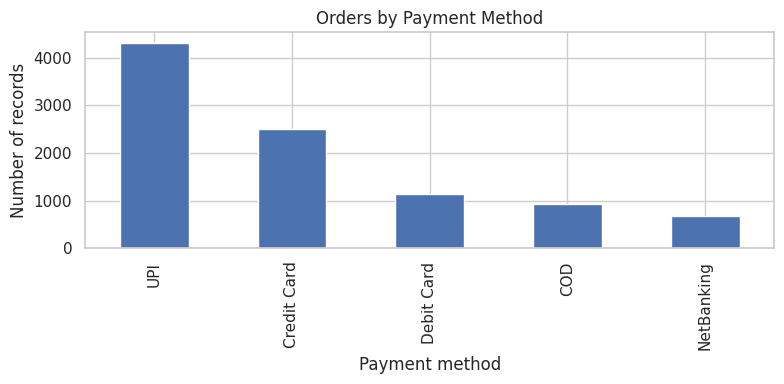

In [15]:
if "coupon_used" in df.columns:
    print(df.groupby("coupon_used")["amount"].agg(
        ["count", "mean", "sum"]
    ))

if "payment_method" in df.columns:
    payment_counts = df["payment_method"].value_counts()

    payment_counts.plot(kind="bar", figsize=(8, 4))
    plt.title("Orders by Payment Method")
    plt.xlabel("Payment method")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

In [16]:
city_category = pd.pivot_table(
    df,
    index="city",
    columns="category",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

display(city_category.head(10))

category,Beauty,Clothing,Electronics,Home,Sports
city,,,,,
Ahmedabad,148730.41,158184.44,1500702.08,380409.03,531058.27
Bengaluru,132523.60,159211.61,1344568.54,447901.15,413694.72
Bhopal,130507.41,127512.06,1177908.91,363200.10,425702.49
Chandigarh,122144.98,165587.47,1502718.81,422599.04,466311.49
Chennai,154805.92,171656.76,1510254.84,508780.72,442962.56
Delhi,96993.22,169200.96,1286719.14,317497.20,615724.58
Dubai,82229.42,138857.77,1448857.66,486156.78,371869.28
Gurugram,115613.25,144566.22,1350547.25,360025.34,490892.84
Hyderabad,136225.01,151810.48,1429286.08,379335.97,420272.23


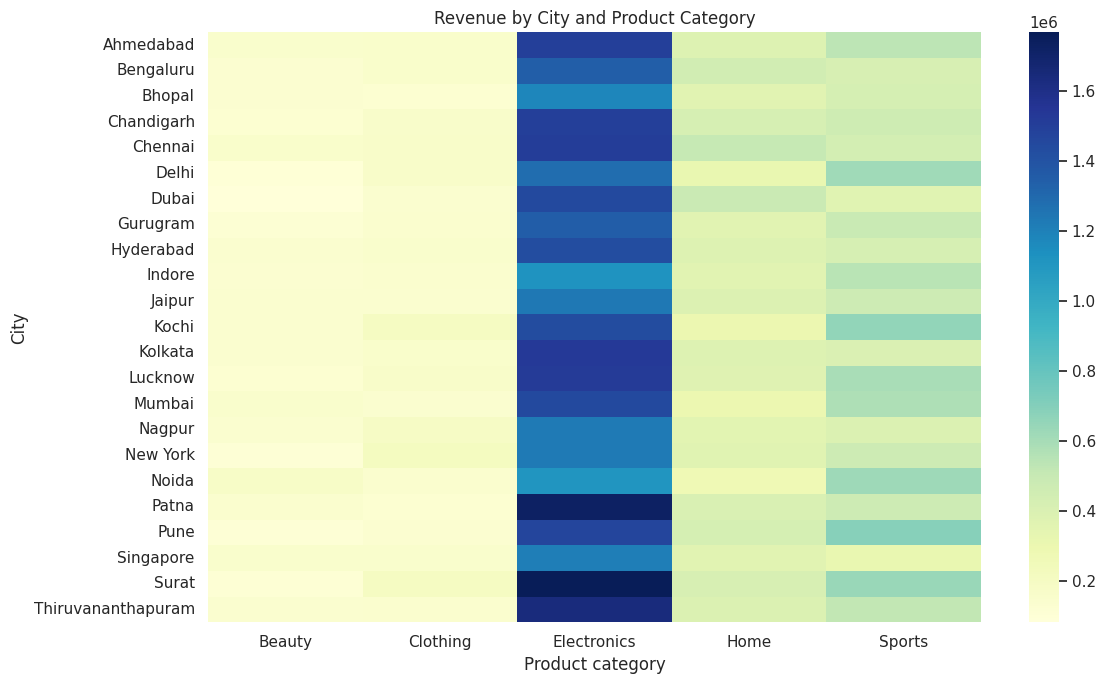

In [17]:
plt.figure(figsize=(12, 7))
sns.heatmap(city_category, cmap="YlGnBu")
plt.title("Revenue by City and Product Category")
plt.xlabel("Product category")
plt.ylabel("City")
plt.tight_layout()
plt.show()

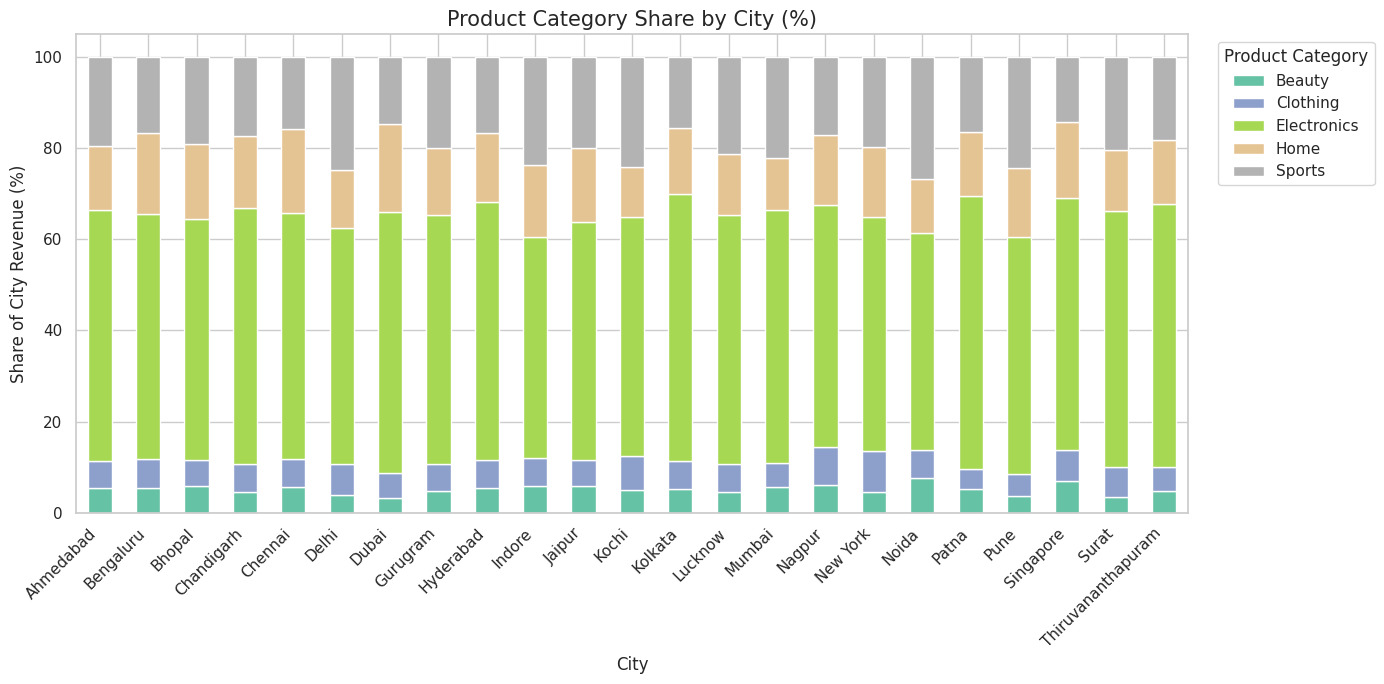

In [19]:

city_category_pct = city_category.div(
    city_category.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

city_category_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    colormap="Set2"
)

plt.title("Product Category Share by City (%)", fontsize=15)
plt.xlabel("City")
plt.ylabel("Share of City Revenue (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Product Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [21]:
df.to_csv("/content/cleaned_retail_sales.csv", index=False)
city_sales.to_csv("/content/city_sales_summary.csv")
product_sales.to_csv("/content/product_sales_summary.csv")
category_sales.to_csv("/content/category_sales_summary.csv")

In [24]:

print(city_sales.columns)
print(city_sales.head())


Index(['total_revenue', 'units_sold', 'transactions'], dtype='object')
                    total_revenue  units_sold  transactions
city                                                       
Surat                  3138418.82         685           433
Patna                  2880708.37         656           406
Thiruvananthapuram     2836469.78         685           433
Pune                   2824843.23         590           382
Chennai                2788460.80         681           425


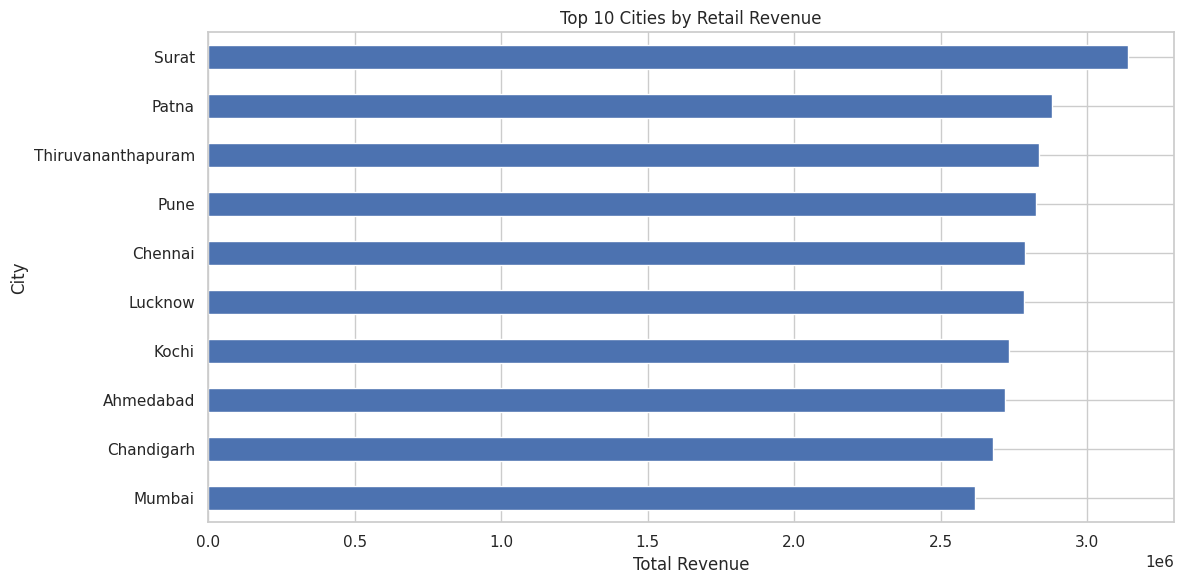

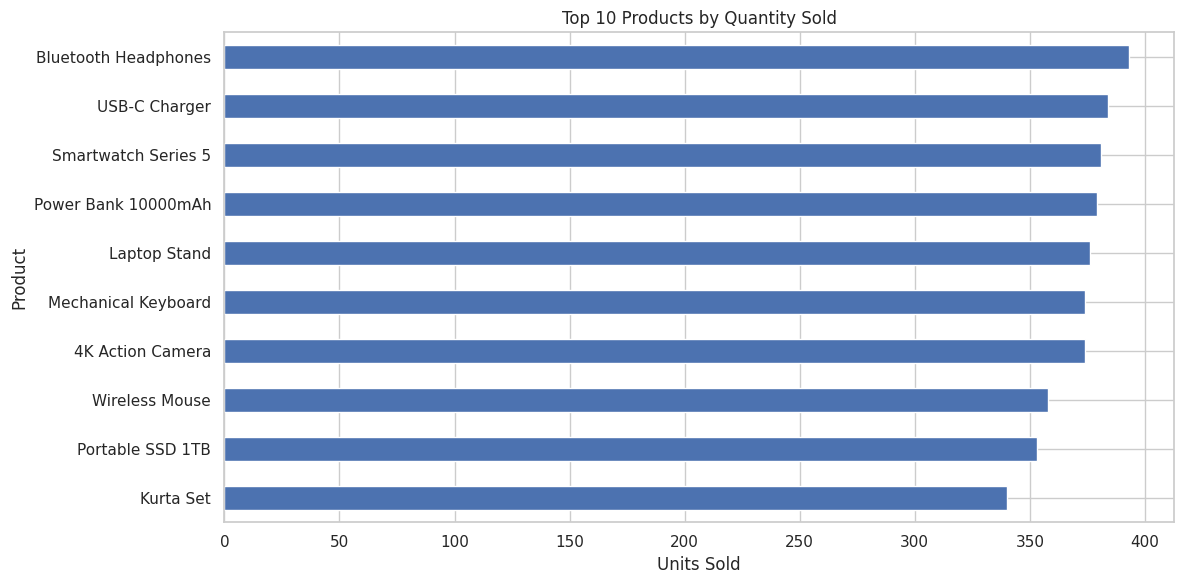

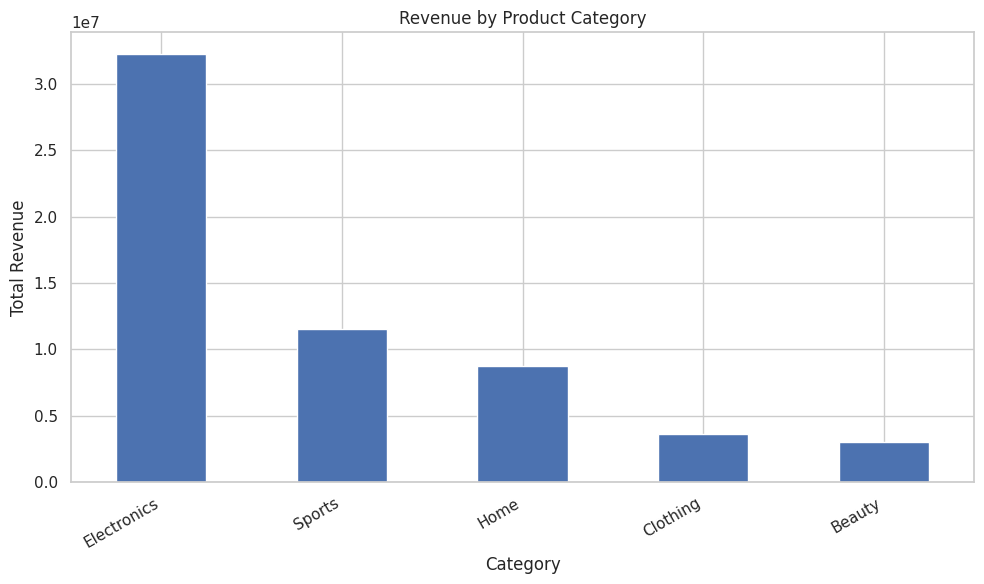

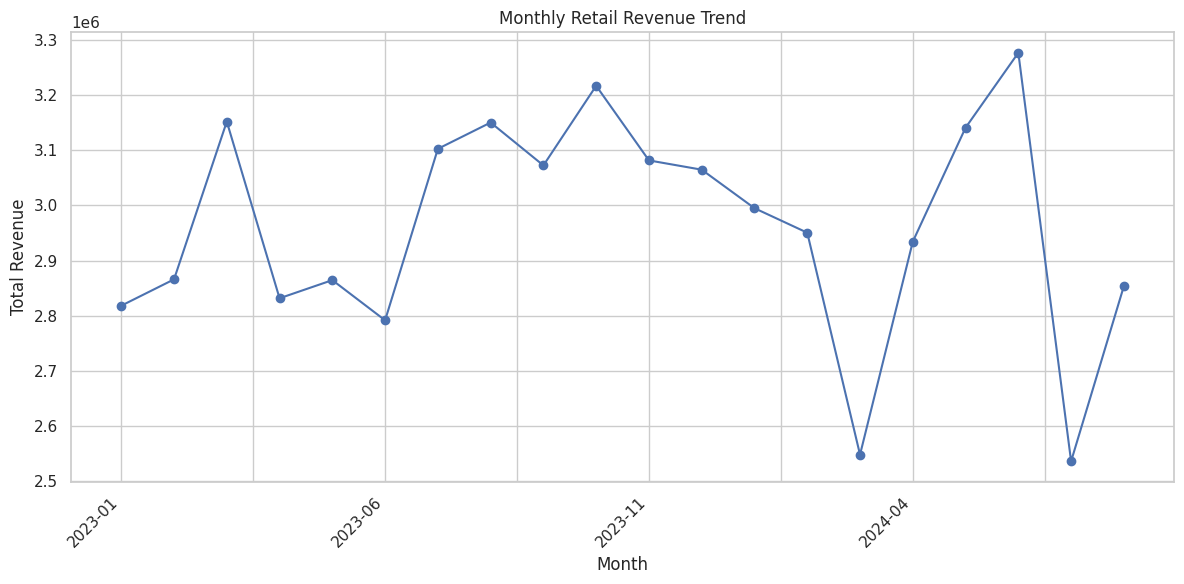

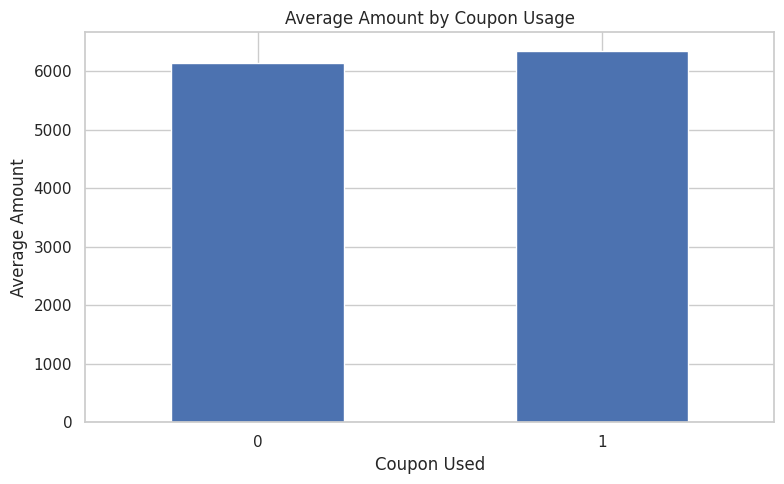

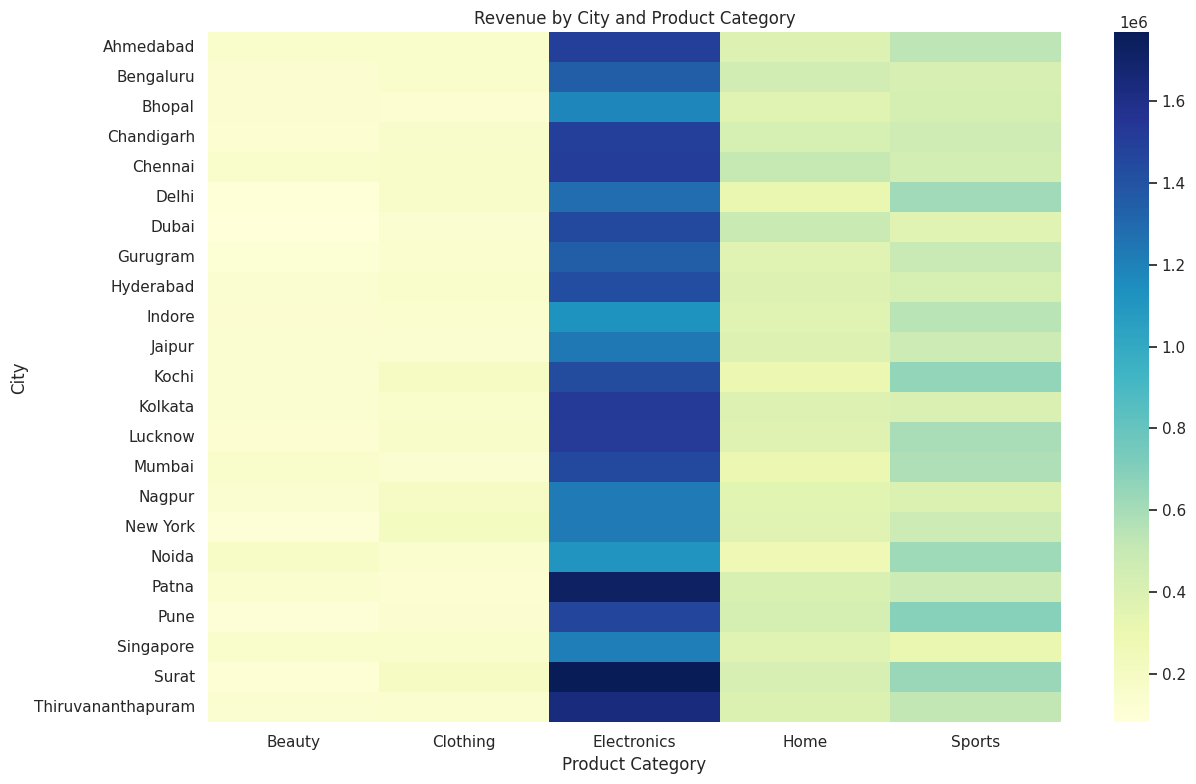

All six graphs and the heatmap have been saved!
Saved files: ['01_city_revenue.png', '04_monthly_trend.png', '06_city_category_heatmap.png', '03_category_revenue.png', '02_top_products.png', '05_coupon_analysis.png']


In [25]:

import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from google.colab import files

# Create folder for all visualizations
folder = "retail_analysis_graphs"
os.makedirs(folder, exist_ok=True)

# 1. Top 10 cities by revenue
plt.figure(figsize=(12, 6))
city_sales["total_revenue"].nlargest(10).sort_values().plot(
    kind="barh"
)
plt.title("Top 10 Cities by Retail Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("City")
plt.tight_layout()
plt.savefig(f"{folder}/01_city_revenue.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 2. Top 10 products by quantity sold
top_products = (
    df.groupby("product_name")["quantity"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(f"{folder}/02_top_products.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 3. Revenue by product category
category_sales = (
    df.groupby("category")["amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{folder}/03_category_revenue.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 4. Monthly revenue trend
monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))["amount"]
    .sum()
)

plt.figure(figsize=(12, 6))
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Retail Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{folder}/04_monthly_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 5. Average transaction amount by coupon usage
coupon_sales = (
    df.groupby("coupon_used")["amount"]
    .mean()
)

plt.figure(figsize=(8, 5))
coupon_sales.plot(kind="bar")
plt.title("Average Amount by Coupon Usage")
plt.xlabel("Coupon Used")
plt.ylabel("Average Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{folder}/05_coupon_analysis.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 6. Revenue by city and product category (heatmap)
city_category = df.pivot_table(
    index="city",
    columns="category",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(13, 8))
sns.heatmap(
    city_category,
    cmap="YlGnBu",
    annot=False,
    fmt=".0f"
)
plt.title("Revenue by City and Product Category")
plt.xlabel("Product Category")
plt.ylabel("City")
plt.tight_layout()
plt.savefig(f"{folder}/06_city_category_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("All six graphs and the heatmap have been saved!")
print("Saved files:", os.listdir(folder))


In [26]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "retail_analysis_graphs",
    "zip",
    root_dir="retail_analysis_graphs"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>